In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Dataset paths
DATASET_ROOT = Path(
    "/kaggle/input/competitions/aptos2019-blindness-detection"
)

TRAIN_CSV = DATASET_ROOT / "train.csv"
TEST_CSV = DATASET_ROOT / "test.csv"

TRAIN_IMAGE_DIR = DATASET_ROOT / "train_images"
TEST_IMAGE_DIR = DATASET_ROOT / "test_images"

# Verify dataset paths
assert TRAIN_CSV.exists(), "Training CSV not found"
assert TEST_CSV.exists(), "Test CSV not found"
assert TRAIN_IMAGE_DIR.is_dir(), "Training image directory not found"
assert TEST_IMAGE_DIR.is_dir(), "Test image directory not found"

print("Dataset paths verified successfully.")
print("Training images:", TRAIN_IMAGE_DIR)
print("Test images:", TEST_IMAGE_DIR)


Dataset paths verified successfully.
Training images: /kaggle/input/competitions/aptos2019-blindness-detection/train_images
Test images: /kaggle/input/competitions/aptos2019-blindness-detection/test_images


In [2]:

# Load dataset metadata
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Training dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nTraining sample:")
display(train_df.head())

print("\nTest sample:")
display(test_df.head())

print("\nMissing values in training data:")
print(train_df.isnull().sum())

print("\nMissing values in test data:")
print(test_df.isnull().sum())


Training dataset shape: (3662, 2)
Test dataset shape: (1928, 1)

Training columns:
['id_code', 'diagnosis']

Test columns:
['id_code']

Training sample:


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0



Test sample:


,id_code
0,0005cfc8afb6
1,003f0afdcd15
2,006efc72b638
3,00836aaacf06
4,009245722fa4



Missing values in training data:
id_code      0
diagnosis    0
dtype: int64

Missing values in test data:
id_code    0
dtype: int64


Image ID: 000c1434d8d7
Original image shape: (2136, 3216, 3)
Image dtype: uint8


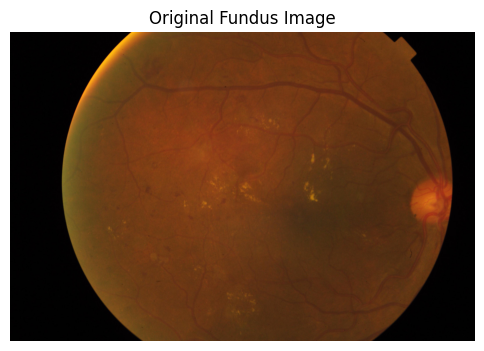

In [3]:

# Select one training image
sample_id = train_df.iloc[0]["id_code"]
sample_path = TRAIN_IMAGE_DIR / f"{sample_id}.png"

# Read image and convert BGR to RGB
original_image = cv2.imread(str(sample_path))
assert original_image is not None, f"Image not found: {sample_path}"

original_image = cv2.cvtColor(
    original_image, cv2.COLOR_BGR2RGB
)

print("Image ID:", sample_id)
print("Original image shape:", original_image.shape)
print("Image dtype:", original_image.dtype)

plt.figure(figsize=(6, 6))
plt.imshow(original_image)
plt.title("Original Fundus Image")
plt.axis("off")
plt.show()


LAB image shape: (2136, 3216, 3)
L channel shape: (2136, 3216)
A channel shape: (2136, 3216)
B channel shape: (2136, 3216)
Class Label:  2


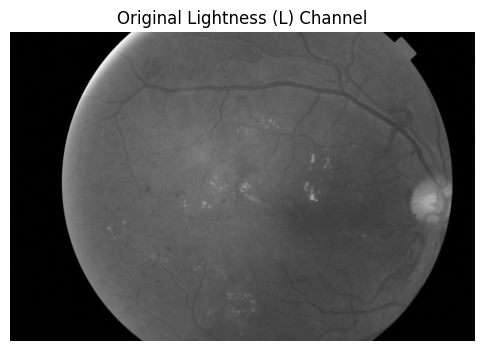

In [4]:

# Convert the original RGB image to LAB color space
lab_image = cv2.cvtColor(original_image, cv2.COLOR_RGB2LAB)

# Split into lightness and color channels
l_channel, a_channel, b_channel = cv2.split(lab_image)

print("LAB image shape:", lab_image.shape)
print("L channel shape:", l_channel.shape)
print("A channel shape:", a_channel.shape)
print("B channel shape:", b_channel.shape)
print("Class Label: ",train_df.loc[train_df["id_code"] == sample_id, "diagnosis"].iloc[0])
plt.figure(figsize=(6, 6))
plt.imshow(l_channel, cmap="gray")
plt.title("Original Lightness (L) Channel")
plt.axis("off")
plt.show()


Luminosity enhancement completed.


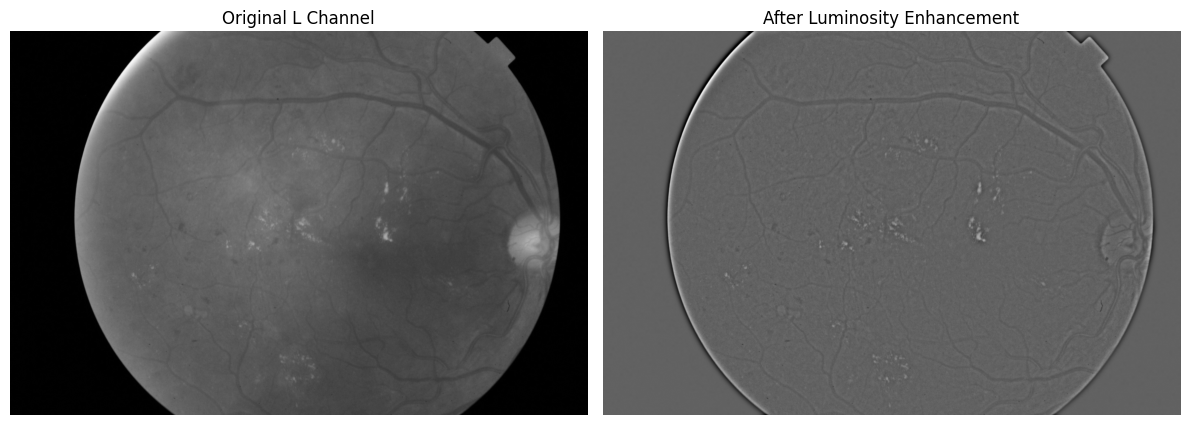

In [5]:

# Luminosity enhancement using local illumination correction

lab_image = cv2.cvtColor(
    original_image, cv2.COLOR_RGB2LAB
)

l_channel, a_channel, b_channel = cv2.split(lab_image)

# Estimate local illumination
local_mean = cv2.GaussianBlur(
    l_channel, (101, 101), sigmaX=0
)

# Target illumination: mean brightness of the L channel
desired_mean = float(np.mean(l_channel))

# Correct uneven illumination
corrected_l = (
    l_channel.astype(np.float32)
    + desired_mean
    - local_mean.astype(np.float32)
)

corrected_l = np.clip(corrected_l, 0, 255).astype(np.uint8)

print("Luminosity enhancement completed.")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(l_channel, cmap="gray")
plt.title("Original L Channel")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(corrected_l, cmap="gray")
plt.title("After Luminosity Enhancement")
plt.axis("off")

plt.tight_layout()
plt.show()


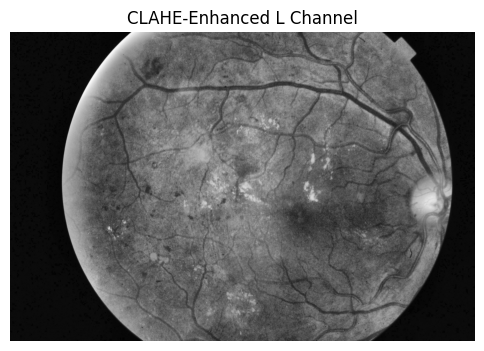

In [6]:
clahe = cv2.createCLAHE(
    clipLimit=5.0,
    tileGridSize=(8, 8)
)

enhanced_l_channel = clahe.apply(l_channel)

plt.figure(figsize=(6, 6))
plt.imshow(enhanced_l_channel, cmap="gray")
plt.title("CLAHE-Enhanced L Channel")
plt.axis("off")
plt.show()

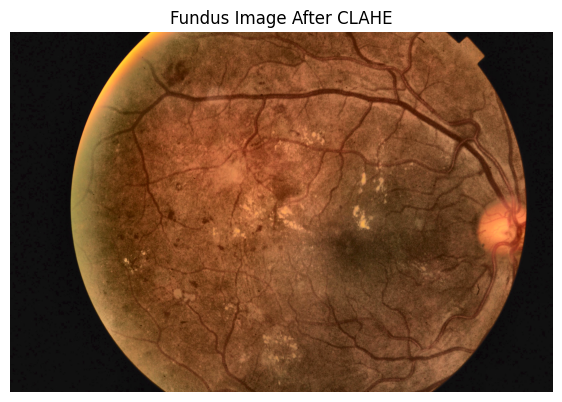

In [7]:
enhanced_lab = cv2.merge([
    enhanced_l_channel,
    a_channel,
    b_channel
])

enhanced_rgb = cv2.cvtColor(
    enhanced_lab, cv2.COLOR_LAB2RGB
)

plt.figure(figsize=(7, 7))
plt.imshow(enhanced_rgb)
plt.title("Fundus Image After CLAHE")
plt.axis("off")
plt.show()

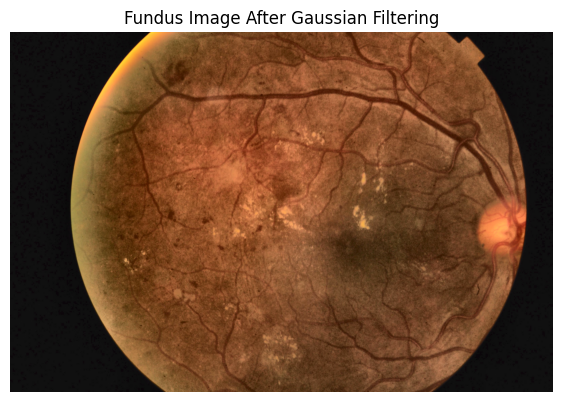

In [8]:

gaussian_image = cv2.GaussianBlur(
    enhanced_rgb,
    (5, 5),
    sigmaX=0
)

plt.figure(figsize=(7, 7))
plt.imshow(gaussian_image)
plt.title("Fundus Image After Gaussian Filtering")
plt.axis("off")
plt.show()


Before cropping: (2136, 3216, 3)
After cropping: (2136, 2703, 3)


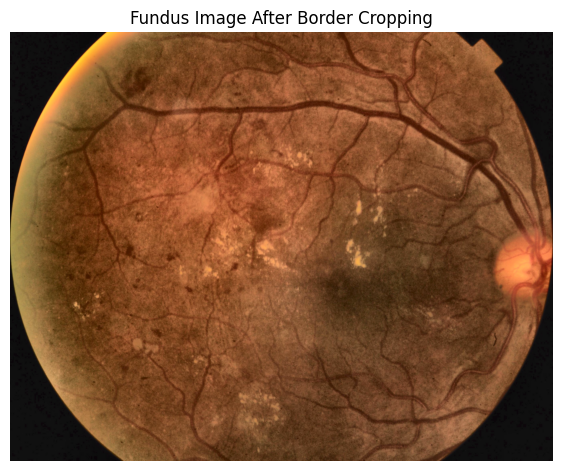

In [9]:
# Use a stronger threshold to ignore dark-border noise
gray_image = cv2.cvtColor(
    gaussian_image, cv2.COLOR_RGB2GRAY
)

mask = gray_image > 40

# Find the bounding box of detected foreground pixels
rows = np.where(mask.any(axis=1))[0]
cols = np.where(mask.any(axis=0))[0]

y_min, y_max = rows[0], rows[-1] + 1
x_min, x_max = cols[0], cols[-1] + 1

cropped_image = gaussian_image[
    y_min:y_max, x_min:x_max
]

print("Before cropping:", gaussian_image.shape)
print("After cropping:", cropped_image.shape)

plt.figure(figsize=(7, 7))
plt.imshow(cropped_image)
plt.title("Fundus Image After Border Cropping")
plt.axis("off")
plt.show()

In [10]:
assert cropped_image is not None
assert cropped_image.size > 0
assert cropped_image.ndim == 3
assert cropped_image.shape[2] == 3

print("Cropping validation passed.")
print("Cropped image shape:", cropped_image.shape)

Cropping validation passed.
Cropped image shape: (2136, 2703, 3)


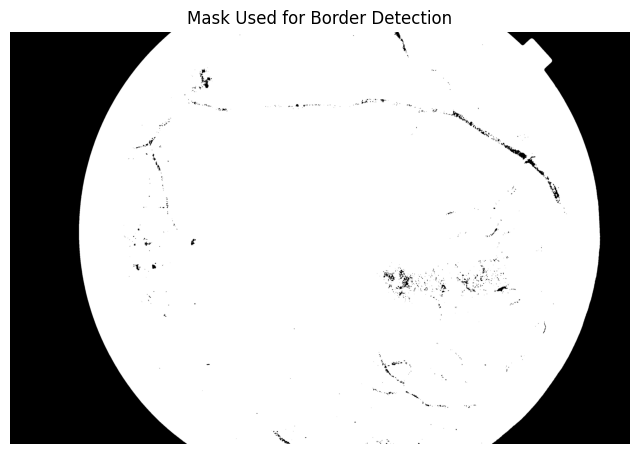

Top row detected: 0
Bottom row detected: 2135
Left column detected: 358
Right column detected: 3060


In [11]:
plt.figure(figsize=(8, 6))
plt.imshow(mask, cmap="gray")
plt.title("Mask Used for Border Detection")
plt.axis("off")
plt.show()

print("Top row detected:", rows[0])
print("Bottom row detected:", rows[-1])
print("Left column detected:", cols[0])
print("Right column detected:", cols[-1])

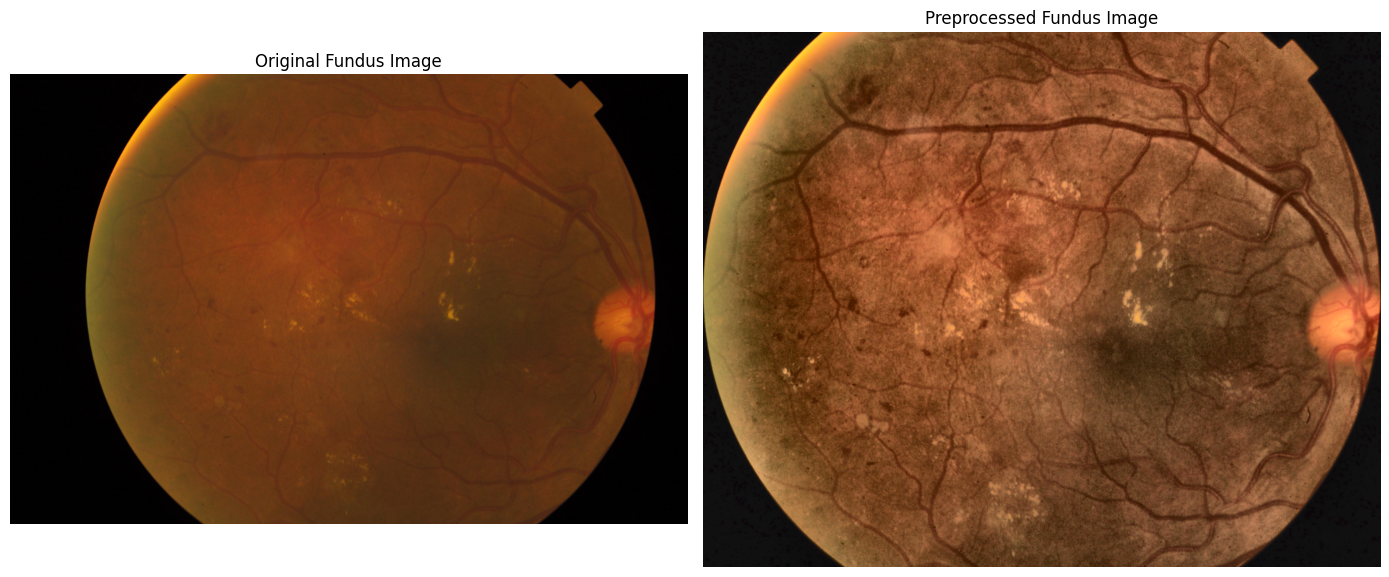

In [12]:

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Fundus Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cropped_image)
plt.title("Preprocessed Fundus Image")
plt.axis("off")

plt.tight_layout()
plt.show()


Resized image shape: (512, 512, 3)


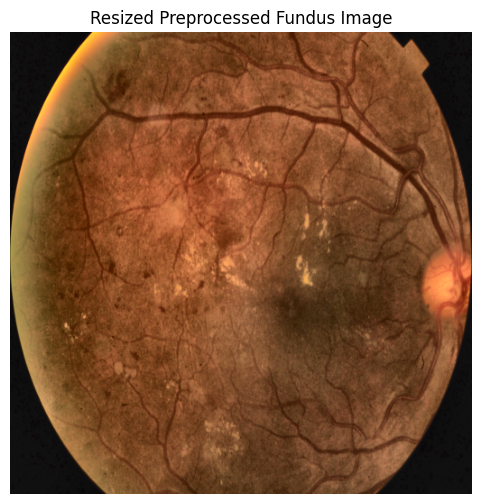

In [13]:
IMG_SIZE = 512

resized_image = cv2.resize(
    cropped_image,
    (IMG_SIZE, IMG_SIZE),
    interpolation=cv2.INTER_AREA
)

print("Resized image shape:", resized_image.shape)

plt.figure(figsize=(6, 6))
plt.imshow(resized_image)
plt.title("Resized Preprocessed Fundus Image")
plt.axis("off")
plt.show()

In [14]:

print("Cropped image shape:", cropped_image.shape)
print("Data type:", cropped_image.dtype)
print("RGB channel means:", cropped_image.mean(axis=(0, 1)))
print("RGB channel standard deviations:", cropped_image.std(axis=(0, 1)))


Cropped image shape: (2136, 2703, 3)
Data type: uint8
RGB channel means: [118.40873437  70.94435784  37.89821148]
RGB channel standard deviations: [48.74829659 30.62795372 18.30495872]


In [15]:

# APTOS training-set RGB statistics
RGB_MEAN = np.array(
    [133.71985309, 79.52423862, 41.30843877],
    dtype=np.float32
)

RGB_STD = np.array(
    [62.56835813, 38.40553729, 29.33583564],
    dtype=np.float32
)

assert np.all(RGB_STD > 0)

print("Training-set normalization statistics.")


Training-set normalization statistics.


In [16]:

# Convert pixel values to float32
image_float = cropped_image.astype(np.float32)

# Standardize each RGB channel using training statistics
normalized_image = (
    image_float - RGB_MEAN
) / RGB_STD

print("Normalized image shape:", normalized_image.shape)
print("Data type:", normalized_image.dtype)
print("Minimum value:", normalized_image.min())
print("Maximum value:", normalized_image.max())
print("Channel means:", normalized_image.mean(axis=(0, 1)))


Normalized image shape: (2136, 2703, 3)
Data type: float32
Minimum value: -2.041285
Maximum value: 3.60562
Channel means: [-0.24423744 -0.2222224  -0.11647177]


In [17]:
assert normalized_image.shape == cropped_image.shape
assert normalized_image.dtype == np.float32
assert np.isfinite(normalized_image).all()

print("Normalization validation passed.")
print("Shape:", normalized_image.shape)
print("Dtype:", normalized_image.dtype)
print("Channel means:", normalized_image.mean(axis=(0, 1)).round(4))
print("Channel standard deviations:", normalized_image.std(axis=(0, 1)).round(4))

Normalization validation passed.
Shape: (2136, 2703, 3)
Dtype: float32
Channel means: [-0.2442 -0.2222 -0.1165]
Channel standard deviations: [0.7767 0.7953 0.6199]


In [18]:

def resize_with_padding(image, target_size=512):
    height, width = image.shape[:2]

    scale = target_size / max(height, width)
    new_width = round(width * scale)
    new_height = round(height * scale)

    resized = cv2.resize(
        image,
        (new_width, new_height),
        interpolation=cv2.INTER_AREA
    )

    canvas = np.zeros(
        (target_size, target_size, 3),
        dtype=image.dtype
    )

    top = (target_size - new_height) // 2
    left = (target_size - new_width) // 2

    canvas[
        top:top + new_height,
        left:left + new_width
    ] = resized

    return canvas

print("resize_with_padding() is defined.")


resize_with_padding() is defined.


In [19]:

def preprocess_fundus(image_path, target_size=512):
    # 1. Load image and convert BGR to RGB
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"Unable to read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # 2. Convert to LAB and apply CLAHE to the L channel
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=5.0,
        tileGridSize=(8, 8)
    )
    enhanced_l = clahe.apply(l_channel)

    # 3. Reconstruct the RGB image
    enhanced_lab = cv2.merge(
        [enhanced_l, a_channel, b_channel]
    )
    enhanced_rgb = cv2.cvtColor(
        enhanced_lab, cv2.COLOR_LAB2RGB
    )

    # 4. Gaussian filtering
    filtered = cv2.GaussianBlur(
        enhanced_rgb, (5, 5), sigmaX=0
    )

    # 5. Crop black borders
    gray = cv2.cvtColor(filtered, cv2.COLOR_RGB2GRAY)
    mask = gray > 40

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    if len(rows) == 0 or len(cols) == 0:
        raise ValueError(f"No foreground detected: {image_path}")

    cropped = filtered[
        rows[0]:rows[-1] + 1,
        cols[0]:cols[-1] + 1
    ]

    # 6. Resize while preserving aspect ratio
    resized = resize_with_padding(cropped, target_size)

    # 7. Normalize using APTOS training-set statistics
    normalized = (
        resized.astype(np.float32) - RGB_MEAN
    ) / RGB_STD

    return normalized


In [20]:

test_ids = train_df["id_code"].head(5).tolist()

for image_id in test_ids:
    image_path = TRAIN_IMAGE_DIR / f"{image_id}.png"
    result = preprocess_fundus(image_path)

    assert result.shape == (512, 512, 3)
    assert result.dtype == np.float32
    assert np.isfinite(result).all()

    print(image_id, "->", result.shape, result.dtype)

print("\nUpdated preprocessing test passed.")


000c1434d8d7 -> (512, 512, 3) float32
001639a390f0 -> (512, 512, 3) float32
0024cdab0c1e -> (512, 512, 3) float32
002c21358ce6 -> (512, 512, 3) float32
005b95c28852 -> (512, 512, 3) float32

Updated preprocessing test passed.


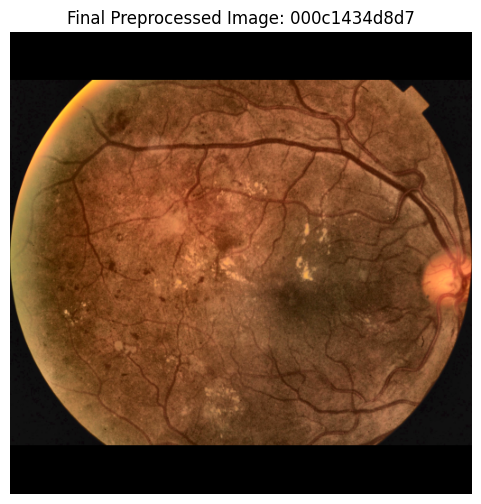

In [21]:
sample_id = test_ids[0]

processed_image = preprocess_fundus(
    TRAIN_IMAGE_DIR / f"{sample_id}.png"
)

# Reverse normalization for display
display_image = processed_image * RGB_STD + RGB_MEAN
display_image = np.clip(display_image, 0, 255).astype(np.uint8)

plt.figure(figsize=(6, 6))
plt.imshow(display_image)
plt.title(f"Final Preprocessed Image: {sample_id}")
plt.axis("off")
plt.show()

In [22]:

# Kaggle working directory (writable)
OUTPUT_ROOT = Path("/kaggle/working/aptos_preprocessed")

TRAIN_OUTPUT_DIR = OUTPUT_ROOT / "train"
TEST_OUTPUT_DIR = OUTPUT_ROOT / "test"

print("Training images:", len(train_df))
print("Test images:", len(test_df))
print("Training output:", TRAIN_OUTPUT_DIR)
print("Test output:", TEST_OUTPUT_DIR)

assert train_df["id_code"].is_unique
assert test_df["id_code"].is_unique
assert train_df["diagnosis"].between(0, 4).all()

print("Metadata validation passed.")


Training images: 3662
Test images: 1928
Training output: /kaggle/working/aptos_preprocessed/train
Test output: /kaggle/working/aptos_preprocessed/test
Metadata validation passed.


In [23]:

TRAIN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TEST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

from tqdm.auto import tqdm

processed_labels = []

for row in tqdm(
    train_df.itertuples(index=False),
    total=len(train_df),
    desc="Preprocessing training images"
):
    image_id = row.id_code
    label = int(row.diagnosis)

    image_path = TRAIN_IMAGE_DIR / f"{image_id}.png"
    processed = preprocess_fundus(image_path)

    # Convert normalized image back to uint8 RGB for JPEG storage
    image_uint8 = np.clip(
        processed * RGB_STD + RGB_MEAN,
        0, 255
    ).astype(np.uint8)

    # OpenCV writes in BGR channel order
    output_path = TRAIN_OUTPUT_DIR / f"{image_id}.jpg"
    success = cv2.imwrite(
        str(output_path),
        cv2.cvtColor(image_uint8, cv2.COLOR_RGB2BGR),
        [cv2.IMWRITE_JPEG_QUALITY, 95]
    )

    if not success:
        raise IOError(f"Failed to save {output_path}")

    processed_labels.append({
        "id_code": image_id,
        "diagnosis": label
    })

processed_train_df = pd.DataFrame(processed_labels)
processed_train_df.to_csv(
    OUTPUT_ROOT / "train_labels.csv",
    index=False
)

print("\nTraining preprocessing complete.")
print("Images saved:", len(processed_train_df))
print("Labels saved:", OUTPUT_ROOT / "train_labels.csv")


Preprocessing training images:   0%|          | 0/3662 [00:00<?, ?it/s]


Training preprocessing complete.
Images saved: 3662
Labels saved: /kaggle/working/aptos_preprocessed/train_labels.csv


In [24]:

saved_train_images = list(TRAIN_OUTPUT_DIR.glob("*.jpg"))
print("Saved training images:", len(saved_train_images))
print("Saved label rows:", len(processed_train_df))

assert len(saved_train_images) == len(train_df)
assert len(processed_train_df) == len(train_df)
assert processed_train_df["id_code"].is_unique

# Check one saved image
sample_saved_path = TRAIN_OUTPUT_DIR / f"{train_df.iloc[0]['id_code']}.jpg"
saved_image = cv2.imread(str(sample_saved_path))

assert saved_image is not None
assert saved_image.shape == (512, 512, 3)

print("Sample saved image shape:", saved_image.shape)
print("Training output verification passed.")


Saved training images: 3662
Saved label rows: 3662
Sample saved image shape: (512, 512, 3)
Training output verification passed.


In [25]:

TEST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for image_id in tqdm(
    test_df["id_code"],
    total=len(test_df),
    desc="Preprocessing test images"
):
    image_path = TEST_IMAGE_DIR / f"{image_id}.png"
    processed = preprocess_fundus(image_path)

    # Convert normalized output back to uint8 RGB for JPEG storage
    image_uint8 = np.clip(
        processed * RGB_STD + RGB_MEAN,
        0, 255
    ).astype(np.uint8)

    output_path = TEST_OUTPUT_DIR / f"{image_id}.jpg"

    success = cv2.imwrite(
        str(output_path),
        cv2.cvtColor(image_uint8, cv2.COLOR_RGB2BGR),
        [cv2.IMWRITE_JPEG_QUALITY, 95]
    )

    if not success:
        raise IOError(f"Failed to save {output_path}")

# Save test ID metadata
test_df.to_csv(
    OUTPUT_ROOT / "test_ids.csv",
    index=False
)

print("\nTest preprocessing complete.")
print("Expected test images:", len(test_df))
print("Saved test images:", len(list(TEST_OUTPUT_DIR.glob("*.jpg"))))


Preprocessing test images:   0%|          | 0/1928 [00:00<?, ?it/s]


Test preprocessing complete.
Expected test images: 1928
Saved test images: 1928


In [26]:

saved_train_count = len(list(TRAIN_OUTPUT_DIR.glob("*.jpg")))
saved_test_count = len(list(TEST_OUTPUT_DIR.glob("*.jpg")))

print("Expected training images:", len(train_df))
print("Saved training images:", saved_train_count)

print("\nExpected test images:", len(test_df))
print("Saved test images:", saved_test_count)

print("\nTraining labels:", len(pd.read_csv(OUTPUT_ROOT / "train_labels.csv")))
print("Test IDs:", len(pd.read_csv(OUTPUT_ROOT / "test_ids.csv")))

assert saved_train_count == len(train_df)
assert saved_test_count == len(test_df)

print("\nFinal dataset verification passed.")
print("Output directory:", OUTPUT_ROOT)


Expected training images: 3662
Saved training images: 3662

Expected test images: 1928
Saved test images: 1928

Training labels: 3662
Test IDs: 1928

Final dataset verification passed.
Output directory: /kaggle/working/aptos_preprocessed


# Notebook 2: Data Preparation and Preprocessing

## Objective
Prepare the APTOS 2019 Blindness Detection images for training ResNet and EfficientNet models.

## Preprocessing steps
1. Load fundus images and convert them to RGB.
2. Convert RGB images to LAB color space.
3. Apply CLAHE to the L channel using a clip limit of 5.0 and an 8 × 8 tile grid.
4. Reconstruct the enhanced RGB image.
5. Apply Gaussian filtering to reduce noise.
6. Crop black borders around the retinal field.
7. Resize images to 512 × 512 while preserving aspect ratio through padding.
8. Normalize using RGB mean and standard deviation calculated from the APTOS training images.
9. Save the processed images and metadata for model training.

## Dataset verification

- Training images processed: 3,662
- Test images processed: 1,928
- Training labels preserved: 3,662
- Test image IDs preserved: 1,928
- Final image dimensions: 512 × 512 × 3

## Output files

- `train/`: Preprocessed training images
- `test/`: Preprocessed test images
- `train_labels.csv`: Training image IDs and diagnosis labels
- `test_ids.csv`: Test image IDs

## Important notes
- Original dataset files remain unchanged.
- Data augmentation will be performed during model training.
- IDRiD will be used for external validation.
- The luminosity-enhancement method from the base paper still requires verification before claiming a complete reproduction.
- The preprocessing pipeline must be kept consistent across training and evaluation datasets.